# Variational Autoencoder (VAE) on Fashion-MNIST with PyTorch

## 1. Setup and Imports

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

import numpy as np
import matplotlib.pyplot as plt

# ---- Reproducibility ----
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# ---- Device: GPU if available, otherwise CPU ----
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

## 2. Load Fashion-MNIST

In [3]:
transform = transforms.ToTensor()   # PIL image -> tensor with values in [0, 1]

train_full = datasets.FashionMNIST(root="./data", train=True,  download=True, transform=transform)
test_set   = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)

# 55,000 for training, 5,000 for validation
train_set, val_set = random_split(
    train_full, [55000, 5000],
    generator=torch.Generator().manual_seed(SEED)
)

BATCH_SIZE = 128
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_set,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False)

class_names = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print(f"Train: {len(train_set)} | Validation: {len(val_set)} | Test: {len(test_set)}")

100%|██████████| 26.4M/26.4M [02:27<00:00, 179kB/s] 
100%|██████████| 29.5k/29.5k [00:00<00:00, 177kB/s]
100%|██████████| 4.42M/4.42M [00:16<00:00, 276kB/s] 
100%|██████████| 5.15k/5.15k [00:00<?, ?B/s]


Train: 55000 | Validation: 5000 | Test: 10000


### Sample Images

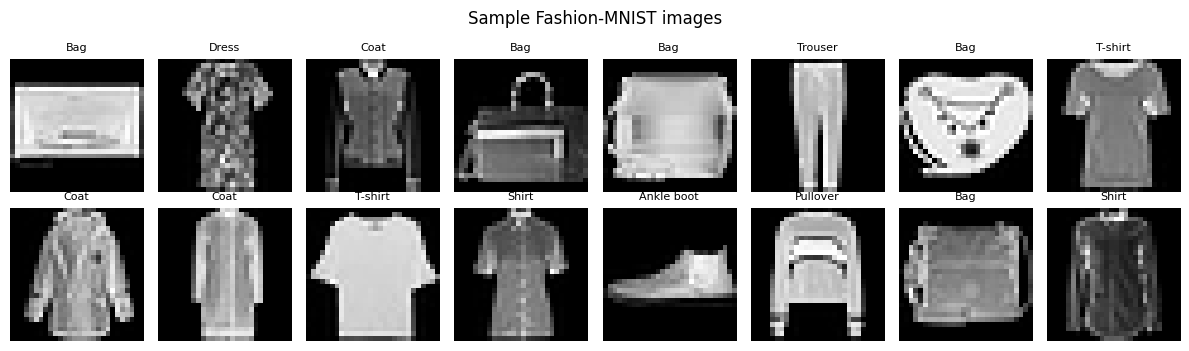

In [6]:
# Quick look at some training images
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 8, figsize=(12, 3.6))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(class_names[labels[i]], fontsize=8)
    ax.axis("off")
plt.suptitle("Sample Fashion-MNIST images")
plt.tight_layout()
plt.show()

## 3. The Model
### a) Encoder: image to a *distribution*
### b) Reparameterization trick
### c) Decoder: latent vector to image

In [7]:
LATENT_DIM = 16   # size of the latent vector z (the bottleneck)

class VAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()

        # ---------- ENCODER: image -> features ----------
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1),    # (1,28,28)  -> (32,14,14)
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),   # (32,14,14) -> (64,7,7)
            nn.ReLU(),
            nn.Flatten(),                                            # (64,7,7)   -> 3136
        )
        # Two separate heads: one predicts the mean, the other the log-variance
        self.fc_mu     = nn.Linear(64 * 7 * 7, latent_dim)
        self.fc_logvar = nn.Linear(64 * 7 * 7, latent_dim)

        # ---------- DECODER: latent vector -> image ----------
        self.decoder_fc = nn.Sequential(
            nn.Linear(latent_dim, 64 * 7 * 7),
            nn.ReLU(),
        )
        self.decoder_conv = nn.Sequential(
            # output_padding=1 makes the size exactly double (7->14, 14->28)
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),  # -> (32,14,14)
            nn.ReLU(),
            nn.ConvTranspose2d(32, 1, kernel_size=3, stride=2, padding=1, output_padding=1),   # -> (1,28,28)
            nn.Sigmoid(),                                            # pixel values in [0, 1]
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)          # mean and log-variance

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)                    # sigma = exp(0.5 * logvar)
        eps = torch.randn_like(std)                      # epsilon ~ N(0, I)
        return mu + eps * std                            # z = mu + sigma * epsilon

    def decode(self, z):
        h = self.decoder_fc(z)
        h = h.view(-1, 64, 7, 7)                         # reshape into a feature map
        return self.decoder_conv(h)

    def forward(self, x):
        mu, logvar = self.encode(x)                      # 1) encode into a distribution
        z = self.reparameterize(mu, logvar)              # 2) sample z (differentiably)
        recon = self.decode(z)                           # 3) decode back to an image
        return recon, mu, logvar

model = VAE().to(device)
print(model)
print(f"\nTotal trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

# Sanity check on shapes
with torch.no_grad():
    r, m, lv = model(torch.zeros(2, 1, 28, 28, device=device))
    print("Reconstruction:", tuple(r.shape), "| mu:", tuple(m.shape), "| logvar:", tuple(lv.shape))

VAE(
  (encoder): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Flatten(start_dim=1, end_dim=-1)
  )
  (fc_mu): Linear(in_features=3136, out_features=16, bias=True)
  (fc_logvar): Linear(in_features=3136, out_features=16, bias=True)
  (decoder_fc): Sequential(
    (0): Linear(in_features=16, out_features=3136, bias=True)
    (1): ReLU()
  )
  (decoder_conv): Sequential(
    (0): ConvTranspose2d(64, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(32, 1, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (3): Sigmoid()
  )
)

Total trainable parameters: 191,265
Reconstruction: (2, 1, 28, 28) | mu: (2, 16) | logvar: (2, 16)


## 4. The VAE Loss (negative ELBO)

In [8]:
BETA = 1.0   # weight of the KL term (1.0 = standard VAE)

def vae_loss(recon, x, mu, logvar, beta=BETA):
    """Returns (total, reconstruction, kl), each summed over the batch."""
    # Reconstruction term: BCE summed over every pixel of every image
    recon_loss = F.binary_cross_entropy(recon, x, reduction="sum")

    # KL divergence between N(mu, sigma^2) and N(0, I), summed over the batch
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())

    total = recon_loss + beta * kl_loss
    return total, recon_loss, kl_loss

## 5. Training

In [9]:
EPOCHS = 15
LEARNING_RATE = 1e-3
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

def run_epoch(loader, train=True):
    """Run one pass over the data. Updates weights if train=True. Returns average per-image losses."""
    model.train() if train else model.eval()
    tot, rec, kl = 0.0, 0.0, 0.0

    with torch.set_grad_enabled(train):                  # no gradients during validation
        for x, _ in loader:                              # labels are ignored
            x = x.to(device)
            recon, mu, logvar = model(x)
            loss, r, k = vae_loss(recon, x, mu, logvar)

            if train:
                optimizer.zero_grad()                    # reset gradients
                (loss / x.size(0)).backward()            # backprop on the per-image loss
                optimizer.step()                         # update weights

            tot += loss.item(); rec += r.item(); kl += k.item()

    n = len(loader.dataset)
    return tot / n, rec / n, kl / n

history = {"train": [], "val": [], "train_rec": [], "train_kl": []}

for epoch in range(1, EPOCHS + 1):
    tr_tot, tr_rec, tr_kl = run_epoch(train_loader, train=True)
    va_tot, _, _          = run_epoch(val_loader,   train=False)

    history["train"].append(tr_tot); history["val"].append(va_tot)
    history["train_rec"].append(tr_rec); history["train_kl"].append(tr_kl)

    print(f"Epoch {epoch:2d}/{EPOCHS} | Train: {tr_tot:7.2f} "
          f"(recon {tr_rec:7.2f}, KL {tr_kl:5.2f}) | Val: {va_tot:7.2f}")

Epoch  1/15 | Train:  289.30 (recon  272.77, KL 16.53) | Val:  258.04
Epoch  2/15 | Train:  253.05 (recon  235.44, KL 17.61) | Val:  250.78
Epoch  3/15 | Train:  248.52 (recon  230.86, KL 17.66) | Val:  248.01
Epoch  4/15 | Train:  246.38 (recon  228.65, KL 17.73) | Val:  246.40
Epoch  5/15 | Train:  244.97 (recon  227.21, KL 17.76) | Val:  245.26
Epoch  6/15 | Train:  244.00 (recon  226.26, KL 17.74) | Val:  244.26
Epoch  7/15 | Train:  243.24 (recon  225.50, KL 17.74) | Val:  243.62
Epoch  8/15 | Train:  242.70 (recon  224.97, KL 17.73) | Val:  243.44
Epoch  9/15 | Train:  242.19 (recon  224.49, KL 17.70) | Val:  242.97
Epoch 10/15 | Train:  241.82 (recon  224.13, KL 17.68) | Val:  242.56
Epoch 11/15 | Train:  241.43 (recon  223.75, KL 17.68) | Val:  242.12
Epoch 12/15 | Train:  241.18 (recon  223.49, KL 17.69) | Val:  241.93
Epoch 13/15 | Train:  240.90 (recon  223.23, KL 17.67) | Val:  241.59
Epoch 14/15 | Train:  240.68 (recon  223.03, KL 17.65) | Val:  241.38
Epoch 15/15 | Train:

## 6. Learning Curves

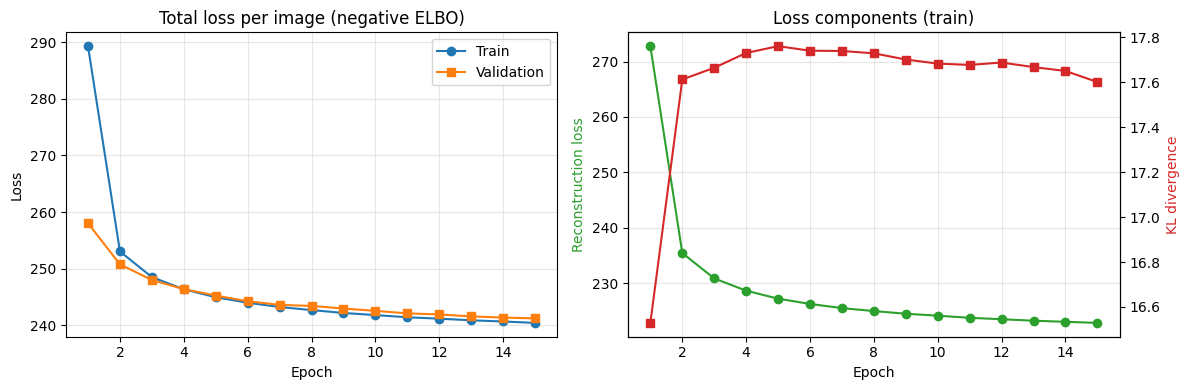

In [10]:
epochs = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history["train"], marker="o", label="Train")
axes[0].plot(epochs, history["val"],   marker="s", label="Validation")
axes[0].set_title("Total loss per image (negative ELBO)")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[0].grid(alpha=0.3); axes[0].legend()

axes[1].plot(epochs, history["train_rec"], marker="o", color="tab:green", label="Reconstruction (BCE)")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Reconstruction loss", color="tab:green")
axes[1].grid(alpha=0.3)
ax2 = axes[1].twinx()                                    # second y-axis for the KL term
ax2.plot(epochs, history["train_kl"], marker="s", color="tab:red", label="KL divergence")
ax2.set_ylabel("KL divergence", color="tab:red")
axes[1].set_title("Loss components (train)")

plt.tight_layout()
plt.show()

## 7. Reconstructions and Test Loss

Test loss per image: 242.30  (reconstruction 224.33 + KL 17.97)


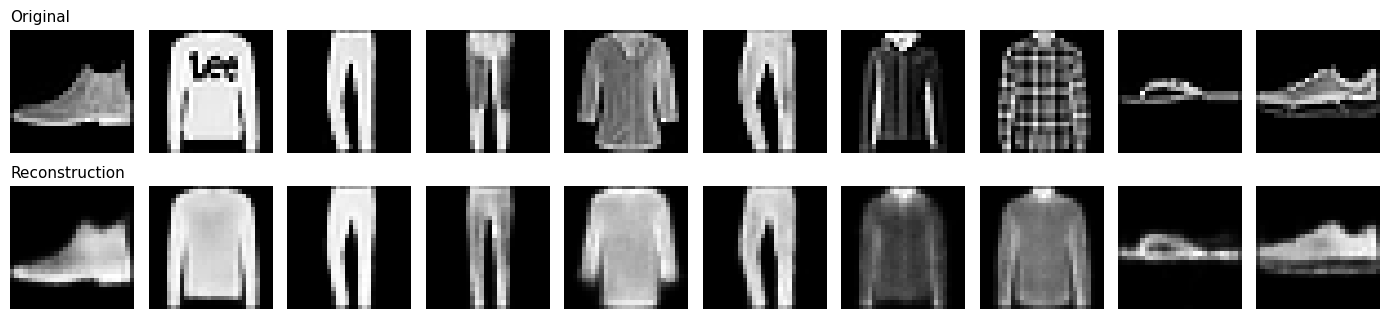

In [11]:
model.eval()
test_tot, test_rec, test_kl = run_epoch(test_loader, train=False)
print(f"Test loss per image: {test_tot:.2f}  (reconstruction {test_rec:.2f} + KL {test_kl:.2f})")

# Show original vs. reconstruction for the first 10 test images
x, y = next(iter(test_loader))
x = x.to(device)
with torch.no_grad():
    recon, _, _ = model(x)

n = 10
fig, axes = plt.subplots(2, n, figsize=(n * 1.4, 3.4))
for i in range(n):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray");     axes[0, i].axis("off")
    axes[1, i].imshow(recon[i].cpu().squeeze(), cmap="gray"); axes[1, i].axis("off")
axes[0, 0].set_title("Original", loc="left", fontsize=11)
axes[1, 0].set_title("Reconstruction", loc="left", fontsize=11)
plt.tight_layout()
plt.show()

## 8. Generating New Images

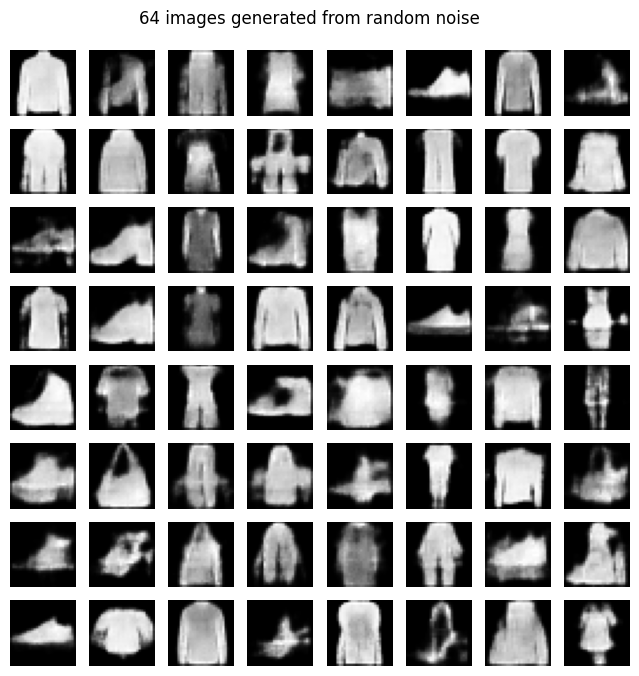

In [12]:
model.eval()
with torch.no_grad():
    z = torch.randn(64, LATENT_DIM, device=device)       # 64 random points from the prior N(0, I)
    generated = model.decode(z).cpu()                    # decode them into images

fig, axes = plt.subplots(8, 8, figsize=(8, 8))
for ax, img in zip(axes.flat, generated):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.axis("off")
plt.suptitle("64 images generated from random noise", y=0.93)
plt.show()

## 9. Latent-Space Interpolation

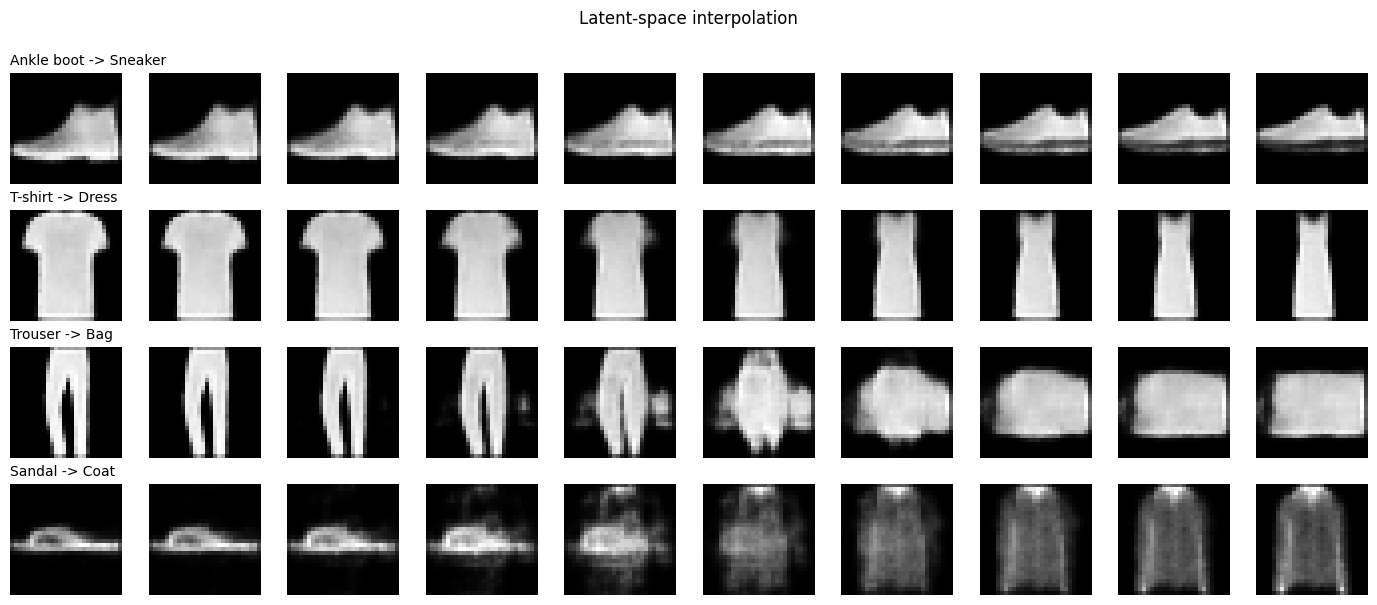

In [13]:
# Collect the whole test set (images + labels) so we can pick images by class
all_x = torch.stack([test_set[i][0] for i in range(len(test_set))])
all_y = test_set.targets

def interpolate(class_a, class_b, steps=10):
    """Interpolate in latent space between the first test image of class_a and class_b."""
    img_a = all_x[(all_y == class_a).nonzero()[0].item()].unsqueeze(0).to(device)
    img_b = all_x[(all_y == class_b).nonzero()[0].item()].unsqueeze(0).to(device)
    with torch.no_grad():
        mu_a, _ = model.encode(img_a)                    # use the mean as the image's latent code
        mu_b, _ = model.encode(img_b)
        ts = torch.linspace(0, 1, steps, device=device).view(-1, 1)
        z = (1 - ts) * mu_a + ts * mu_b                  # points along the straight line
        return model.decode(z).cpu()

pairs = [(9, 7),   # ankle boot  -> sneaker
         (0, 3),   # T-shirt     -> dress
         (1, 8),   # trouser     -> bag
         (5, 4)]   # sandal      -> coat

fig, axes = plt.subplots(len(pairs), 10, figsize=(14, 6))
for r, (a, b) in enumerate(pairs):
    imgs = interpolate(a, b)
    for c in range(10):
        axes[r, c].imshow(imgs[c].squeeze(), cmap="gray")
        axes[r, c].axis("off")
    axes[r, 0].set_title(f"{class_names[a]} -> {class_names[b]}", loc="left", fontsize=10)
plt.suptitle("Latent-space interpolation", y=1.0)
plt.tight_layout()
plt.show()

## 10. Visualising the Latent Space

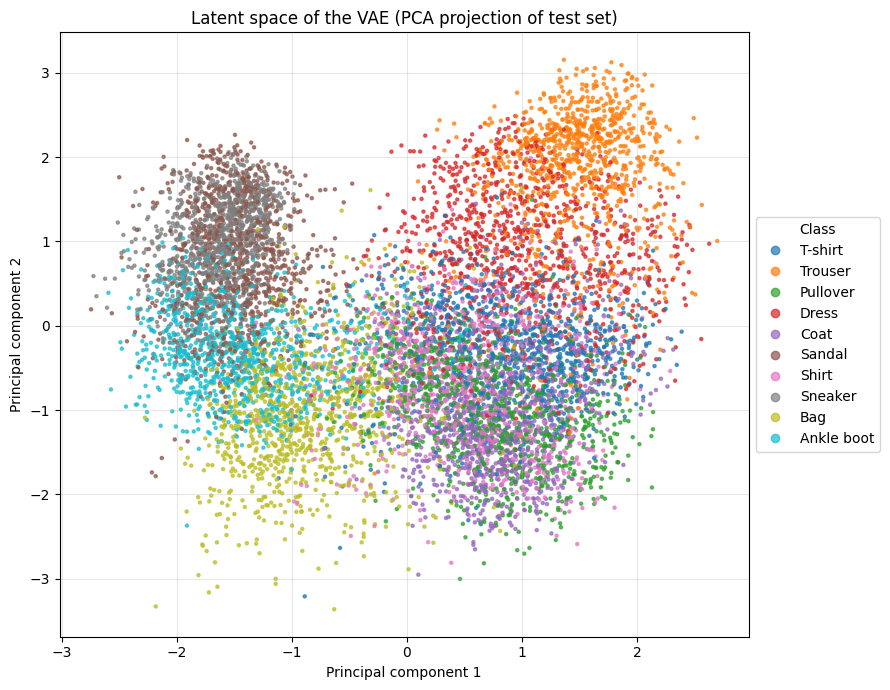

In [14]:
# Encode every test image and keep the latent means (mu)
mus = []
with torch.no_grad():
    for i in range(0, len(all_x), 1000):
        mu, _ = model.encode(all_x[i:i + 1000].to(device))
        mus.append(mu.cpu())
mus = torch.cat(mus)                                     # (10000, LATENT_DIM)

# PCA via SVD: centre the data, then project onto the top-2 principal directions
centered = mus - mus.mean(dim=0, keepdim=True)
_, _, Vh = torch.linalg.svd(centered, full_matrices=False)
coords = (centered @ Vh[:2].T).numpy()                   # (10000, 2)

plt.figure(figsize=(9, 7))
scatter = plt.scatter(coords[:, 0], coords[:, 1], c=all_y.numpy(), cmap="tab10", s=5, alpha=0.7)
handles, _ = scatter.legend_elements()
plt.legend(handles, class_names, title="Class", loc="center left", bbox_to_anchor=(1, 0.5))
plt.xlabel("Principal component 1"); plt.ylabel("Principal component 2")
plt.title("Latent space of the VAE (PCA projection of test set)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Save the Model

In [15]:
torch.save(model.state_dict(), "vae_fashion_mnist.pth")
print("Model saved to vae_fashion_mnist.pth")

Model saved to vae_fashion_mnist.pth


## Summary